--- Temperaturstatistikk Ås (2025) ---
 Mean (°C)  Median (°C)  Min (°C)  Max (°C)
       7.9          8.4     -15.5      23.7


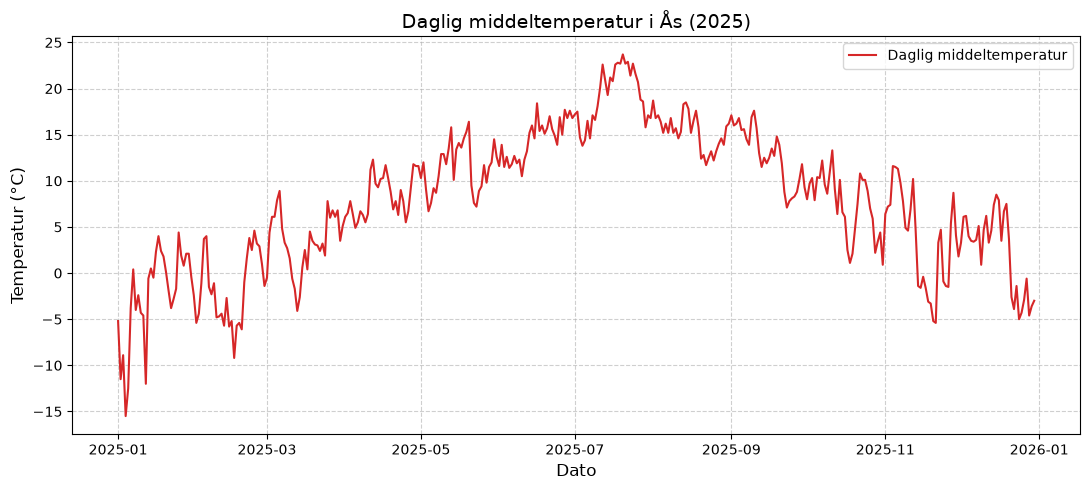

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import requests

# 1. Les inn din skjulte Client-ID fra tekstfilen
with open('../client_id.txt', 'r') as f:
    client_id = f.read().strip()

# 2. Definer endepunkt og parametere spesifisert i oppgaven
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',                    # Værstasjon for Ås
    'elements': 'mean(air_temperature P1D)', # Daglig middeltemperatur
    'referencetime': '2025-01-01/2025-12-31' # Hele året 2025
}

# 3. Hent data fra Frost API
r = requests.get(endpoint, parameters, auth=(client_id, ''))
json_data = r.json()

# Sjekk at forespørselen gikk bra
if r.status_code == 200:
    # 4. Pakk ut observasjonsdataene til en DataFrame
    data_list = []
    for item in json_data['data']:
        data_list.append({
            'referenceTime': item['referenceTime'],
            'temperature': item['observations'][0]['value']
        })

    df_2025 = pd.DataFrame(data_list)
    df_2025['referenceTime'] = pd.to_datetime(df_2025['referenceTime'])

    # 5. Lag sammendragstabell med mean, median, min og max
    summary_table = pd.DataFrame({
        'Mean (°C)': [df_2025['temperature'].mean()],
        'Median (°C)': [df_2025['temperature'].median()],
        'Min (°C)': [df_2025['temperature'].min()],
        'Max (°C)': [df_2025['temperature'].max()]
    })

    # Skriv ut tabellen med print()
    print("--- Temperaturstatistikk Ås (2025) ---")
    print(summary_table.round(2).to_string(index=False))

    # 6. Lag plott for daglig middeltemperatur (tid på x-aksen, temp på y-aksen)
    plt.figure(figsize=(11, 5))
    plt.plot(df_2025['referenceTime'], df_2025['temperature'], color='tab:red', linewidth=1.5, label='Daglig middeltemperatur')
    
    plt.title('Daglig middeltemperatur i Ås (2025)', fontsize=14)
    plt.xlabel('Dato', fontsize=12)
    plt.ylabel('Temperatur (°C)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print(f"Feil ved henting av data. Statuskode: {r.status_code}")
    print(json_data.get('error', {}).get('message', 'Ukjent feil'))

--- Nedbørstatistikk Ås (2025) ---
 Totalt (mm)  Snitt per dag (mm)  Maks på én dag (mm)
       942.2                 2.6                 36.1


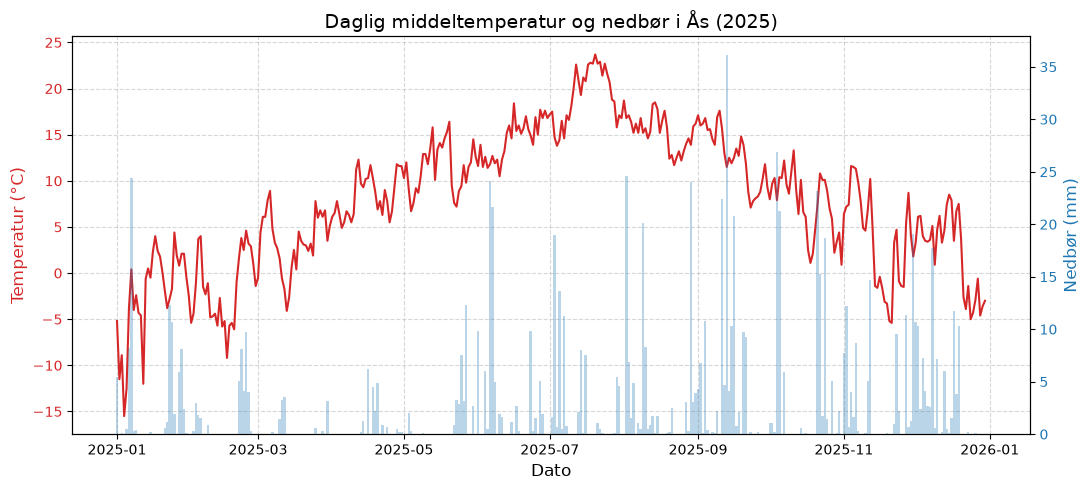

In [ ]:
# --- OPPGAVE 2 ---

# 1. Henter nedbørsdata for 2025
parameters_precip = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31'
}

r_precip = requests.get(endpoint, parameters_precip, auth=(client_id, ''))

if r_precip.status_code == 200:
    # 2. Legg nedbørsverdiene rett inn i den eksisterende df_2025-tabellen din
    precip_data = [item['observations'][0]['value'] for item in r_precip.json()['data']]
    df_2025['precipitation'] = precip_data

    # 3. Sammendragstabell for nedbør
    precip_summary = pd.DataFrame({
        'Totalt (mm)': [df_2025['precipitation'].sum()],
        'Snitt per dag (mm)': [df_2025['precipitation'].mean()],
        'Maks på én dag (mm)': [df_2025['precipitation'].max()]
    })

    print("--- Nedbørstatistikk Ås (2025) ---")
    print(precip_summary.round(1).to_string(index=False))

    # 4. Kombinert plott med to Y-akser (Temperatur + Nedbør)
    fig, ax1 = plt.subplots(figsize=(11, 5))

    # Venstre y-akse: Temperatur (Rød linje fra Oppgave 1)
    ax1.set_xlabel('Dato', fontsize=12)
    ax1.set_ylabel('Temperatur (°C)', color='tab:red', fontsize=12)
    ax1.plot(df_2025['referenceTime'], df_2025['temperature'], color='tab:red', linewidth=1.5, label='Temperatur')
    ax1.tick_params(axis='y', labelcolor='tab:red')

    # Høyre y-akse: Nedbør (Blå søyler)
    ax2 = ax1.twinx()
    ax2.set_ylabel('Nedbør (mm)', color='tab:blue', fontsize=12)
    ax2.bar(df_2025['referenceTime'], df_2025['precipitation'], color='tab:blue', alpha=0.3, width=1.0, label='Nedbør')
    ax2.tick_params(axis='y', labelcolor='tab:blue')

    plt.title('Daglig middeltemperatur og nedbør i Ås (2025)', fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

else:
    print("Feil ved henting av nedbør data.")

=== SAMMENLIGNING AV TEMPERATUR (1925 vs 2025) ===
         År  Mean (°C)  Median (°C)  Min (°C)  Max (°C)
       1925       5.31          5.3     -20.7      24.3
       2025       7.90          8.4     -15.5      23.7
Endring (Δ)       2.59          3.1       5.2      -0.6


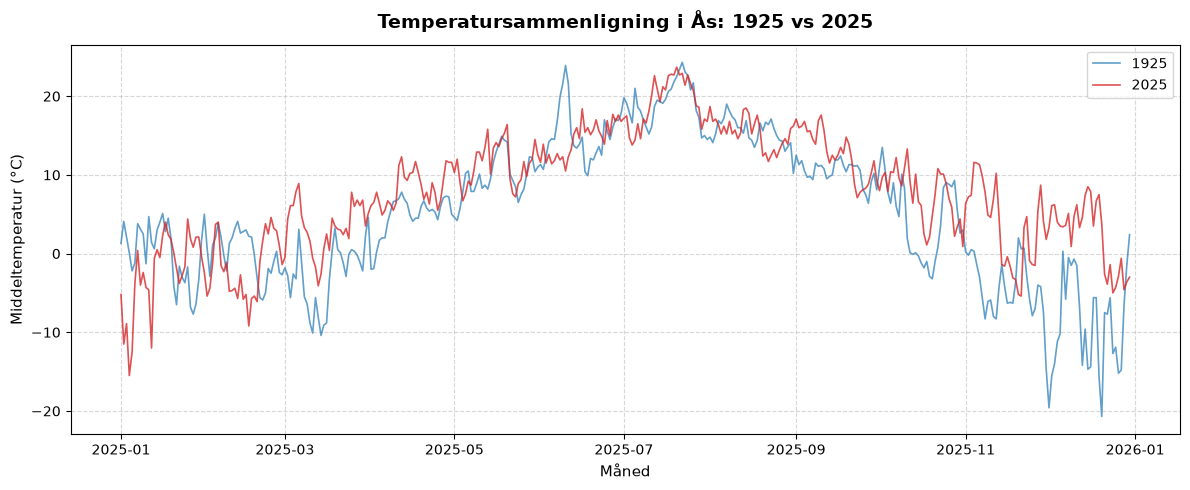

In [4]:
# --- OPPGAVE 3 ---
# (Bruker gjenbrukte variabler som client_id, endpoint og df_2025 fra tidligere celler)

# 1. Hent temperaturdata for 1925 (100 år tidligere)
parameters_1925 = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '1925-01-01/1925-12-31'
}

r_1925 = requests.get(endpoint, parameters_1925, auth=(client_id, ''))

if r_1925.status_code == 200:
    # 2. Pakk ut 1925-dataene til en egen DataFrame
    data_1925 = []
    for item in r_1925.json()['data']:
        data_1925.append({
            'referenceTime': item['referenceTime'],
            'temperature': item['observations'][0]['value']
        })

    df_1925 = pd.DataFrame(data_1925)
    df_1925['referenceTime'] = pd.to_datetime(df_1925['referenceTime'])

    # 3. Lag sammenligningstabell for 1925 vs 2025
    summary_compare = pd.DataFrame({
        'År': ['1925', '2025', 'Endring (Δ)'],
        'Mean (°C)': [
            df_1925['temperature'].mean(), 
            df_2025['temperature'].mean(),
            df_2025['temperature'].mean() - df_1925['temperature'].mean()
        ],
        'Median (°C)': [
            df_1925['temperature'].median(), 
            df_2025['temperature'].median(),
            df_2025['temperature'].median() - df_1925['temperature'].median()
        ],
        'Min (°C)': [
            df_1925['temperature'].min(), 
            df_2025['temperature'].min(),
            df_2025['temperature'].min() - df_1925['temperature'].min()
        ],
        'Max (°C)': [
            df_1925['temperature'].max(), 
            df_2025['temperature'].max(),
            df_2025['temperature'].max() - df_1925['temperature'].max()
        ]
    })

    print("=== SAMMENLIGNING AV TEMPERATUR (1925 vs 2025) ===")
    print(summary_compare.round(2).to_string(index=False))
    print("=" * 50)

    # 4. Tilpass datoene for 1925 slik at begge kan plottes på samme tidsakse (Jan - Des)
    df_1925['plot_date'] = df_1925['referenceTime'].apply(lambda x: x.replace(year=2025))

    # 5. Sammenligningsplott
    plt.figure(figsize=(12, 5))
    plt.plot(df_1925['plot_date'], df_1925['temperature'], color='tab:blue', alpha=0.7, linewidth=1.2, label='1925')
    plt.plot(df_2025['referenceTime'], df_2025['temperature'], color='tab:red', alpha=0.8, linewidth=1.2, label='2025')

    plt.title('Temperatursammenligning i Ås: 1925 vs 2025', fontsize=14, fontweight='bold', pad=12)
    plt.xlabel('Måned', fontsize=11)
    plt.ylabel('Middeltemperatur (°C)', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

else:
    print("Feil ved henting av data for 1925.")

In [ ]:
import pandas as pd
import yaml


# 1. Definer en frikoblet funksjon for varmebølger
def finn_og_lagre_varmebolger(df, temp_col='temperature', date_col='referenceTime', 
                               terskel=20.0, min_dager=3, filnavn='varmebolger.yml'):
    """
    Finner varmebølger (minst 'min_dager' på rad med temp >= 'terskel')
    og lagrer oppsummeringen til en YAML-fil.
    """
    varmebolger = []
    naavaerende_bolge = []

    for _, rad in df.iterrows():
        temp = rad[temp_col]
        dato = rad[date_col].strftime('%Y-%m-%d') if hasattr(rad[date_col], 'strftime') else str(rad[date_col])

        if temp >= terskel:
            naavaerende_bolge.append({'dato': dato, 'temp': float(temp)})
        else:
            if len(naavaerende_bolge) >= min_dager:
                varmebolger.append({
                    'start_dato': naavaerende_bolge[0]['dato'],
                    'slutt_dato': naavaerende_bolge[-1]['dato'],
                    'varighet_dager': len(naavaerende_bolge),
                    'maks_temp': max(d['temp'] for d in naavaerende_bolge),
                    'snitt_temp': round(sum(d['temp'] for d in naavaerende_bolge) / len(naavaerende_bolge), 2)
                })
            naavaerende_bolge = []

    # Sjekk om en varmebølge pågikk helt til siste dag i datsettet
    if len(naavaerende_bolge) >= min_dager:
        varmebolger.append({
            'start_dato': naavaerende_bolge[0]['dato'],
            'slutt_dato': naavaerende_bolge[-1]['dato'],
            'varighet_dager': len(naavaerende_bolge),
            'maks_temp': max(d['temp'] for d in naavaerende_bolge),
            'snitt_temp': round(sum(d['temp'] for d in naavaerende_bolge) / len(naavaerende_bolge), 2)
        })

    # Strukturer dataene for YAML-eksport
    resultat_data = {
        'kriterier': {
            'temperatur_terskel_C': terskel,
            'minimum_sammenhengende_dager': min_dager
        },
        'totalt_antall_varmebolger': len(varmebolger),
        'varmebolger_detaljer': varmebolger
    }

    # Lagre til YAML-fil
    with open(filnavn, 'w', encoding='utf-8') as f:
        yaml.dump(resultat_data, f, default_flow_style=False, allow_unicode=True, sort_keys=False)

    print(f"Søk ferdig: Fant {len(varmebolger)} varmebølge(r) (terskel ≥ {terskel}°C i minst {min_dager} dager).")
    print(f"Resultatene er lagret til filen '{filnavn}'.\n")
    return resultat_data


# 2. Kjør funksjonen på 2025-dataene fra tidligere oppgave
rapport_2025 = finn_og_lagre_varmebolger(df_2025, terskel=20.0, min_dager=3, filnavn='varmebolger_2025.yml')

# 3. Les og vis innholdet i YAML-filen direkte i notebook-en for å verifisere
print("--- INNHOLD I 'varmebolger_2025.yml' ---")
with open('varmebolger_2025.yml', 'r', encoding='utf-8') as f:
    print(f.read())

Søk ferdig: Fant 2 varmebølge(r) (terskel ≥ 20.0°C i minst 3 dager).
Resultatene er lagret til filen 'varmebolger_2025.yml'.

--- INNHOLD I 'varmebolger_2025.yml' ---
kriterier:
  temperatur_terskel_C: 20.0
  minimum_sammenhengende_dager: 3
totalt_antall_varmebolger: 2
varmebolger_detaljer:
- start_dato: '2025-07-11'
  slutt_dato: '2025-07-13'
  varighet_dager: 3
  maks_temp: 22.6
  snitt_temp: 21.2
- start_dato: '2025-07-15'
  slutt_dato: '2025-07-26'
  varighet_dager: 12
  maks_temp: 23.7
  snitt_temp: 22.15



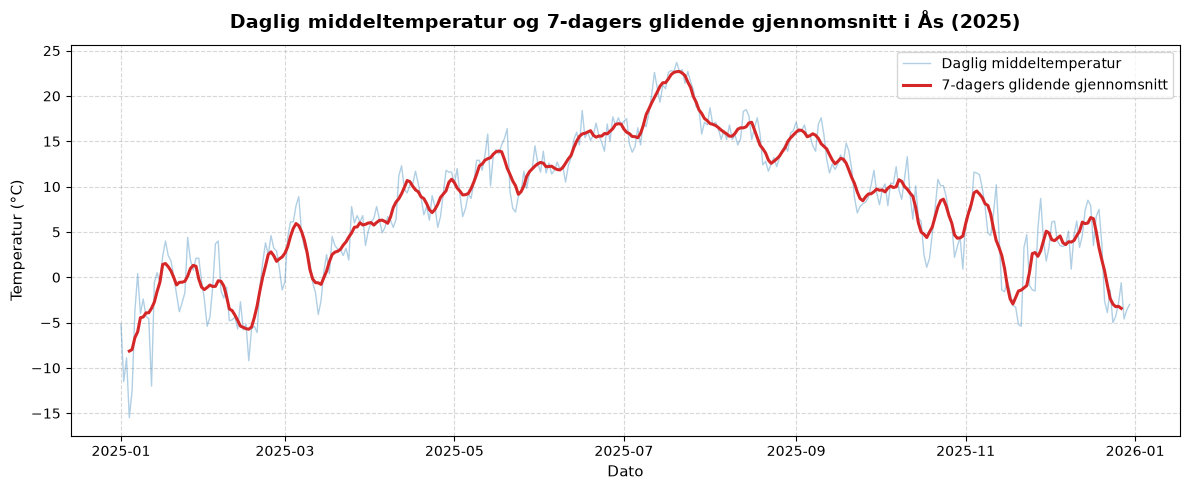

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# --- OPPGAVE 5: 7-dagers glidende gjennomsnitt ---

# 1. Beregn 7-dagers glidende gjennomsnitt
df_2025['temp_7d_snitt'] = df_2025['temperature'].rolling(window=7, center=True).mean()

# 2. Plott daglig middeltemperatur mot 7-dagers snitt
plt.figure(figsize=(12, 5))

# Daglig middeltemperatur (lysere linje i bakgrunnen)
plt.plot(df_2025['referenceTime'], df_2025['temperature'], color='tab:blue', alpha=0.35, linewidth=1, label='Daglig middeltemperatur')

# Glidende gjennomsnitt (tykk og tydelig linje)
plt.plot(df_2025['referenceTime'], df_2025['temp_7d_snitt'], color='tab:red', linewidth=2.2, label='7-dagers glidende gjennomsnitt')

plt.title('Daglig middeltemperatur og 7-dagers glidende gjennomsnitt i Ås (2025)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Dato', fontsize=11)
plt.ylabel('Temperatur (°C)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()